In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv("/content/social_media_ad_optimization.csv")

In [3]:
df.head()

,user_id,age,gender,location,interests,ad_id,ad_category,ad_platform,ad_type,impressions,clicks,conversion,time_spent_on_ad,day_of_week,device_type,engagement_score
0,U0001,58,M,USA,Food,A0001,Sportswear,Facebook,Image,3,0,0,3.38,Friday,Mobile,0.02
1,U0002,55,F,USA,Tech,A0002,Electronics,Facebook,Image,9,9,1,6.77,Saturday,Tablet,0.93
2,U0003,52,F,UK,Gaming,A0003,Luggage,Instagram,Image,13,12,1,13.26,Wednesday,Mobile,0.93
3,U0004,31,F,USA,Tech,A0004,Gadgets,Facebook,Video,14,5,0,24.41,Saturday,Desktop,0.28
4,U0005,52,M,India,Tech,A0005,Luggage,Instagram,Carousel,10,5,0,21.43,Monday,Tablet,0.35


In [3]:
df.shape

(500, 16)

In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 16 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   user_id           500 non-null    object 
 1   age               500 non-null    int64  
 2   gender            500 non-null    object 
 3   location          500 non-null    object 
 4   interests         500 non-null    object 
 5   ad_id             500 non-null    object 
 6   ad_category       500 non-null    object 
 7   ad_platform       500 non-null    object 
 8   ad_type           500 non-null    object 
 9   impressions       500 non-null    int64  
 10  clicks            500 non-null    int64  
 11  conversion        500 non-null    int64  
 12  time_spent_on_ad  500 non-null    float64
 13  day_of_week       500 non-null    object 
 14  device_type       500 non-null    object 
 15  engagement_score  500 non-null    float64
dtypes: float64(2), int64(4), object(10)
memory u

In [4]:
df.describe().round(2)

,age,impressions,clicks,conversion,time_spent_on_ad,engagement_score
count,500.00,500.00,500.00,500.00,500.00,500.00
mean,39.41,8.28,4.52,0.47,14.07,0.52
std,12.40,4.22,3.73,0.50,9.09,0.31
min,18.00,1.00,0.00,0.00,0.46,0.00
25%,28.00,4.75,1.00,0.00,4.99,0.27
50%,39.00,9.00,4.00,0.00,13.28,0.55
75%,51.00,12.00,7.00,1.00,21.73,0.77
max,60.00,15.00,15.00,1.00,29.95,1.00


In [5]:
df.isnull().sum()

,0
user_id,0
age,0
gender,0
location,0
interests,0
ad_id,0
ad_category,0
ad_platform,0
ad_type,0
impressions,0


In [6]:
df.duplicated().sum()

np.int64(0)

In [7]:
df["CTR"]= (df["clicks"]/df["impressions"]*100).round(2)
df["CTR"]

,CTR
0,0.00
1,100.00
2,92.31
3,35.71
4,50.00
...,...
495,33.33
496,0.00
497,100.00
498,88.89


In [8]:
df["conversion_rate"]=np.where(df["clicks"]>0,(df["conversion"]/df["clicks"]*100).round(2),np.nan)
df["conversion_rate"]

,conversion_rate
0,NaN
1,11.11
2,8.33
3,0.00
4,0.00
...,...
495,50.00
496,NaN
497,0.00
498,0.00


In [10]:
numeric_cols = [
    "age",
    "impressions",
    "clicks",
    "time_spent_on_ad",
    "engagement_score"
]

for col in numeric_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)

    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    outliers = df[(df[col] < lower) | (df[col] > upper)]

    print(f"{col}")
    print(f"Lower bound: {lower:.2f}")
    print(f"Upper bound: {upper:.2f}")
    print(f"Number of outliers: {len(outliers)}")
    print("-" * 40)

age
Lower bound: -6.50
Upper bound: 85.50
Number of outliers: 0
----------------------------------------
impressions
Lower bound: -6.12
Upper bound: 22.88
Number of outliers: 0
----------------------------------------
clicks
Lower bound: -8.00
Upper bound: 16.00
Number of outliers: 0
----------------------------------------
time_spent_on_ad
Lower bound: -20.12
Upper bound: 46.85
Number of outliers: 0
----------------------------------------
engagement_score
Lower bound: -0.48
Upper bound: 1.53
Number of outliers: 0
----------------------------------------


In [11]:
df["ad_platform"].unique()

array(['Facebook', 'Instagram'], dtype=object)

In [12]:
df.groupby("ad_platform")["clicks"].sum()

,clicks
ad_platform,
Facebook,1086
Instagram,1174


In [13]:
df.groupby("ad_platform")["CTR"].mean()

,CTR
ad_platform,
Facebook,52.352846
Instagram,55.568622


In [14]:
df.groupby("ad_platform")["engagement_score"].mean()

,engagement_score
ad_platform,
Facebook,0.501992
Instagram,0.537874


In [15]:
df.groupby("ad_platform")["conversion"].sum()

,conversion
ad_platform,
Facebook,110
Instagram,125


In [16]:
bins = [17,24,34,44,54,100]
labels = ["18-24","25-34","35-44","45-54","55+"]
df["Age_Group"]=pd.cut(
   df["age"],
   bins=bins,
    labels=labels
)
df.Age_Group

,Age_Group
0,55+
1,55+
2,45-54
3,25-34
4,45-54
...,...
495,35-44
496,35-44
497,18-24
498,18-24


In [17]:
df.groupby(["ad_platform","Age_Group"])["engagement_score"].mean().round(2)

/tmp/ipykernel_2750/4168163568.py:1: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df.groupby(["ad_platform","Age_Group"])["engagement_score"].mean().round(2)


ad_platform  Age_Group
Facebook     18-24        0.50
             25-34        0.51
             35-44        0.51
             45-54        0.48
             55+          0.50
Instagram    18-24        0.54
             25-34        0.57
             35-44        0.49
             45-54        0.53
             55+          0.55
Name: engagement_score, dtype: float64

In [18]:
df.groupby(["ad_platform","Age_Group"])["conversion"].mean().round(2)

/tmp/ipykernel_2750/934548432.py:1: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df.groupby(["ad_platform","Age_Group"])["conversion"].mean().round(2)


ad_platform  Age_Group
Facebook     18-24        0.41
             25-34        0.52
             35-44        0.47
             45-54        0.40
             55+          0.41
Instagram    18-24        0.44
             25-34        0.55
             35-44        0.49
             45-54        0.48
             55+          0.44
Name: conversion, dtype: float64

In [19]:
df.groupby(["ad_platform","gender"])["engagement_score"].mean().round(2)

ad_platform  gender
Facebook     F         0.53
             M         0.47
             Other     0.51
Instagram    F         0.54
             M         0.53
             Other     0.54
Name: engagement_score, dtype: float64

In [20]:
df.groupby(["ad_platform","gender"])["conversion"].mean().round(2)

ad_platform  gender
Facebook     F         0.42
             M         0.44
             Other     0.48
Instagram    F         0.47
             M         0.47
             Other     0.53
Name: conversion, dtype: float64

In [21]:
df.groupby(
    ["ad_platform", "device_type"]
)["CTR"].mean().round(2)

ad_platform  device_type
Facebook     Desktop        50.37
             Mobile         49.60
             Tablet         57.42
Instagram    Desktop        53.04
             Mobile         55.28
             Tablet         58.76
Name: CTR, dtype: float64

In [22]:
df.groupby(
    ["ad_platform", "device_type"]
)["conversion"].mean().round(2)

ad_platform  device_type
Facebook     Desktop        0.51
             Mobile         0.42
             Tablet         0.42
Instagram    Desktop        0.51
             Mobile         0.56
             Tablet         0.41
Name: conversion, dtype: float64

In [23]:
df.groupby(
    ["ad_platform", "ad_type"]
)["CTR"].mean().round(2)



ad_platform  ad_type 
Facebook     Carousel    50.16
             Image       55.35
             Video       50.94
Instagram    Carousel    51.69
             Image       57.41
             Video       57.63
Name: CTR, dtype: float64

In [24]:
df.groupby(
    ["ad_platform", "ad_type"]
)["engagement_score"].mean().round(2)

ad_platform  ad_type 
Facebook     Carousel    0.51
             Image       0.52
             Video       0.47
Instagram    Carousel    0.50
             Image       0.57
             Video       0.53
Name: engagement_score, dtype: float64

In [25]:
df.groupby(
    ["ad_platform", "ad_category"]
)["CTR"].mean().round(2)



ad_platform  ad_category    
Facebook     Apparel            50.76
             Electronics        59.92
             Food & Beverage    43.55
             Gadgets            52.58
             Luggage            55.31
             Sportswear         51.36
Instagram    Apparel            49.99
             Electronics        51.73
             Food & Beverage    56.41
             Gadgets            53.93
             Luggage            57.07
             Sportswear         64.36
Name: CTR, dtype: float64

In [26]:


df.groupby(
    ["ad_platform", "ad_category"]
)["conversion"].mean().round(2)

ad_platform  ad_category    
Facebook     Apparel            0.51
             Electronics        0.49
             Food & Beverage    0.46
             Gadgets            0.40
             Luggage            0.34
             Sportswear         0.53
Instagram    Apparel            0.35
             Electronics        0.45
             Food & Beverage    0.57
             Gadgets            0.47
             Luggage            0.52
             Sportswear         0.57
Name: conversion, dtype: float64

In [27]:
df.groupby("interests")["engagement_score"].mean().round(2)

,engagement_score
interests,
Fashion,0.59
Fitness,0.50
Food,0.53
Gaming,0.53
Tech,0.48
Travel,0.51


In [28]:
df.groupby("interests")["conversion"].mean().round(2)

,conversion
interests,
Fashion,0.54
Fitness,0.43
Food,0.49
Gaming,0.51
Tech,0.41
Travel,0.46


In [29]:
df.groupby(["interests","ad_platform"])["conversion"].mean().round(2)

interests  ad_platform
Fashion    Facebook       0.57
           Instagram      0.52
Fitness    Facebook       0.45
           Instagram      0.41
Food       Facebook       0.48
           Instagram      0.51
Gaming     Facebook       0.51
           Instagram      0.51
Tech       Facebook       0.37
           Instagram      0.45
Travel     Facebook       0.35
           Instagram      0.55
Name: conversion, dtype: float64

In [30]:
df.groupby("location")["conversion"].mean().round(2).sort_values(ascending=False)

,conversion
location,
Canada,0.55
Australia,0.54
Germany,0.50
India,0.40
USA,0.40
UK,0.39


In [31]:
df.groupby(["location","ad_platform"])["conversion"].mean().round().sort_values(ascending=False)

location   ad_platform
Australia  Facebook       1.0
           Instagram      1.0
Canada     Facebook       1.0
           Instagram      1.0
Germany    Instagram      1.0
           Facebook       0.0
India      Facebook       0.0
           Instagram      0.0
UK         Facebook       0.0
           Instagram      0.0
USA        Facebook       0.0
           Instagram      0.0
Name: conversion, dtype: float64

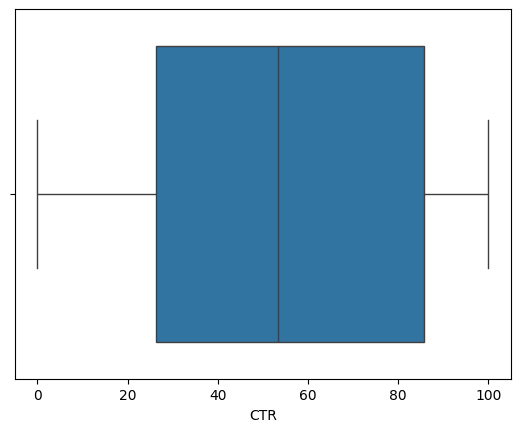

In [32]:
sns.boxplot(x=df['CTR'])
plt.show()

In [33]:
df[[
    "time_spent_on_ad",
    "engagement_score",
    "clicks",
    "conversion"
]].corr()

,time_spent_on_ad,engagement_score,clicks,conversion
time_spent_on_ad,1.000000,0.405386,0.244856,0.196670
engagement_score,0.405386,1.000000,0.517068,0.813367
clicks,0.244856,0.517068,1.000000,0.159055
conversion,0.196670,0.813367,0.159055,1.000000


<Axes: xlabel='time_spent_on_ad', ylabel='engagement_score'>

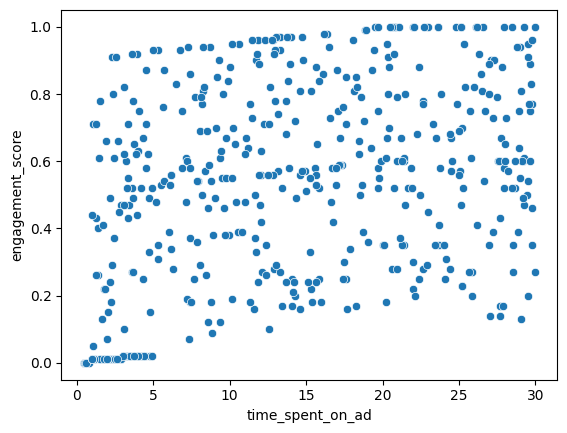

In [34]:
sns.scatterplot(
    data=df,
    x="time_spent_on_ad",
    y="engagement_score"
)

<Axes: xlabel='time_spent_on_ad', ylabel='conversion'>

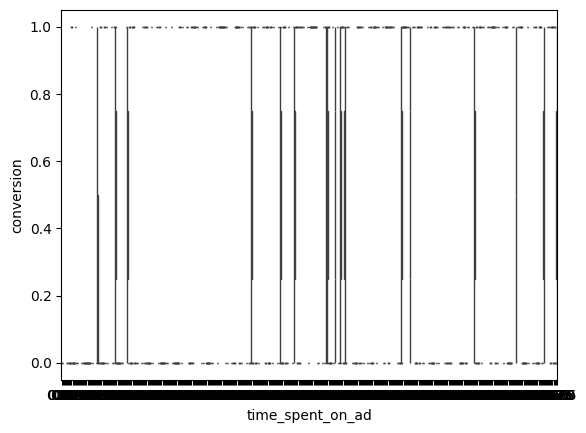

In [35]:
sns.boxplot(
    data=df,
    x="time_spent_on_ad",
    y="conversion"
)

In [36]:
if "CTR" not in df.columns:
    df["CTR"] = (df["clicks"] / df["impressions"] * 100).round(2)

numeric_cols = [
    "age",
    "impressions",
    "clicks",
    "conversion",
    "time_spent_on_ad",
    "engagement_score",
    "CTR"
]

corr = df[numeric_cols].corr()
corr

,age,impressions,clicks,conversion,time_spent_on_ad,engagement_score,CTR
age,1.000000,-0.076404,0.019095,-0.042813,-0.081756,-0.021736,0.028031
impressions,-0.076404,1.000000,0.620806,0.054909,0.161684,0.073131,0.034099
clicks,0.019095,0.620806,1.000000,0.159055,0.244856,0.517068,0.691318
conversion,-0.042813,0.054909,0.159055,1.000000,0.196670,0.813367,0.244693
time_spent_on_ad,-0.081756,0.161684,0.244856,0.196670,1.000000,0.405386,0.301682
engagement_score,-0.021736,0.073131,0.517068,0.813367,0.405386,1.000000,0.753629
CTR,0.028031,0.034099,0.691318,0.244693,0.301682,0.753629,1.000000


In [37]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")

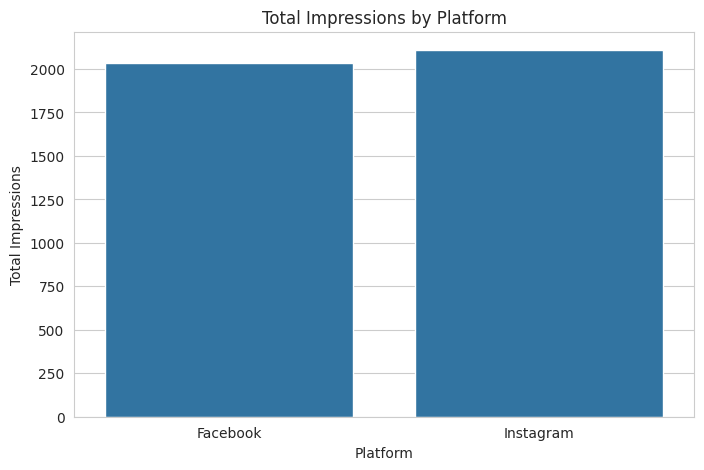

In [38]:
platform_impressions = df.groupby("ad_platform")["impressions"].sum().reset_index()

plt.figure(figsize=(8,5))

sns.barplot(
    data=platform_impressions,
    x="ad_platform",
    y="impressions"
)

plt.title("Total Impressions by Platform")
plt.xlabel("Platform")
plt.ylabel("Total Impressions")

plt.show()

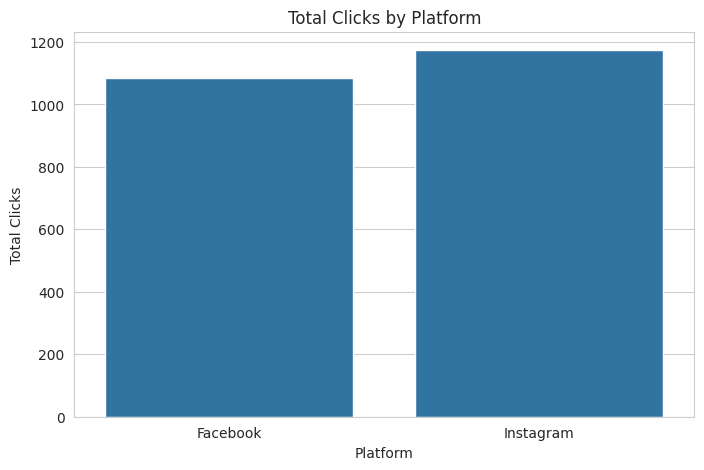

In [39]:
platform_clicks = df.groupby("ad_platform")["clicks"].sum().reset_index()

plt.figure(figsize=(8,5))

sns.barplot(
    data=platform_clicks,
    x="ad_platform",
    y="clicks"
)

plt.title("Total Clicks by Platform")
plt.xlabel("Platform")
plt.ylabel("Total Clicks")

plt.show()

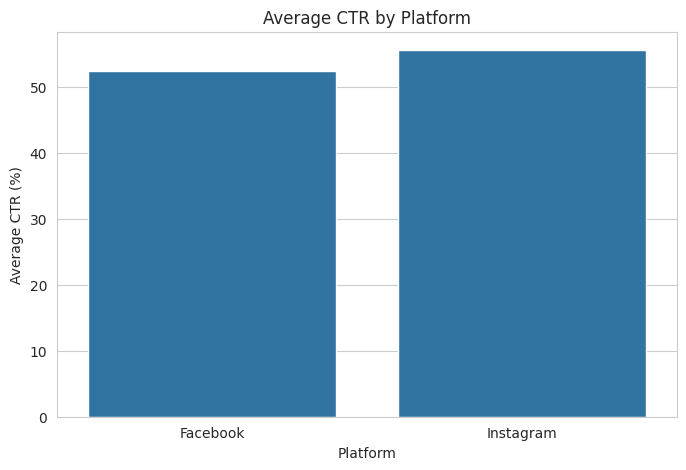

In [40]:
platform_ctr = df.groupby("ad_platform")["CTR"].mean().reset_index()

plt.figure(figsize=(8,5))

sns.barplot(
    data=platform_ctr,
    x="ad_platform",
    y="CTR"
)

plt.title("Average CTR by Platform")
plt.xlabel("Platform")
plt.ylabel("Average CTR (%)")

plt.show()

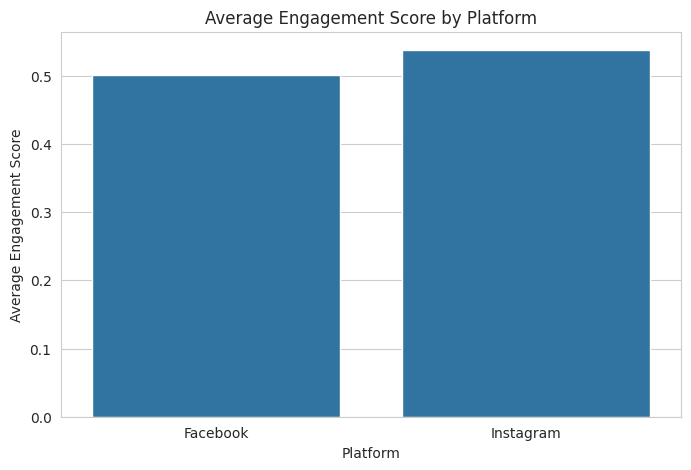

In [41]:
platform_engagement = df.groupby("ad_platform")["engagement_score"].mean().reset_index()

plt.figure(figsize=(8,5))

sns.barplot(
    data=platform_engagement,
    x="ad_platform",
    y="engagement_score"
)

plt.title("Average Engagement Score by Platform")
plt.xlabel("Platform")
plt.ylabel("Average Engagement Score")

plt.show()

In [42]:
platform_conversion = df.groupby("ad_platform").agg(
    clicks=("clicks", "sum"),
    conversions=("conversion", "sum")
).reset_index()

platform_conversion["conversion_rate"] = (
    platform_conversion["conversions"] /
    platform_conversion["clicks"] * 100
)

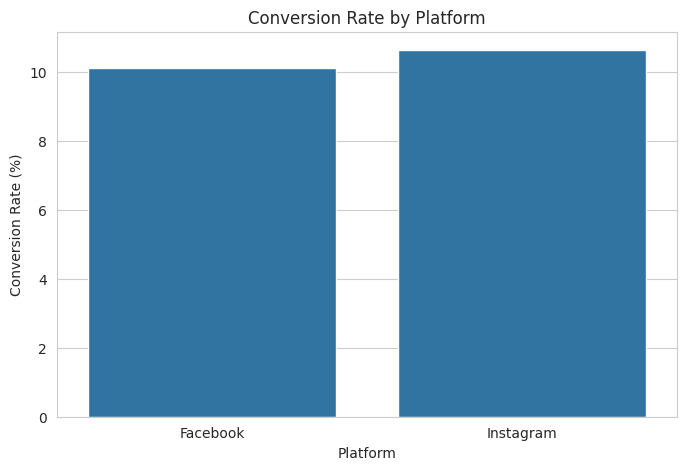

In [43]:
platform_conversion = df.groupby("ad_platform").agg(
    clicks=("clicks", "sum"),
    conversions=("conversion", "sum")
).reset_index()

platform_conversion["conversion_rate"] = (
    platform_conversion["conversions"] /
    platform_conversion["clicks"] * 100
)

plt.figure(figsize=(8,5))

sns.barplot(
    data=platform_conversion,
    x="ad_platform",
    y="conversion_rate"
)

plt.title("Conversion Rate by Platform")
plt.xlabel("Platform")
plt.ylabel("Conversion Rate (%)")

plt.show()

In [44]:
bins = [17, 24, 34, 44, 54, 100]

labels = [
    "18-24",
    "25-34",
    "35-44",
    "45-54",
    "55+"
]

df["Age_Group"] = pd.cut(
    df["age"],
    bins=bins,
    labels=labels
)

/tmp/ipykernel_2750/2032309724.py:1: FutureWarning: The default value of observed=False is deprecated and will change to observed=True in a future version of pandas. Specify observed=False to silence this warning and retain the current behavior
  age_platform = df.pivot_table(


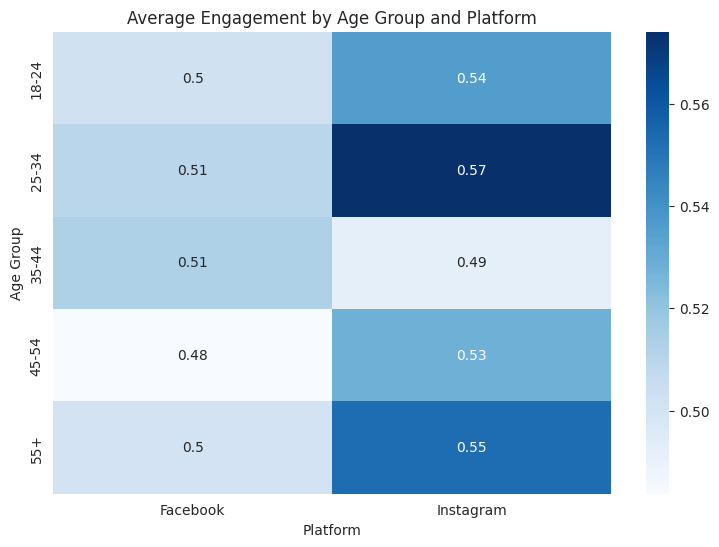

In [45]:
age_platform = df.pivot_table(
    index="Age_Group",
    columns="ad_platform",
    values="engagement_score",
    aggfunc="mean"
)

plt.figure(figsize=(9,6))

sns.heatmap(
    age_platform,
    annot=True,
    cmap="Blues"
)

plt.title("Average Engagement by Age Group and Platform")
plt.xlabel("Platform")
plt.ylabel("Age Group")

plt.show()

/tmp/ipykernel_2750/3432903513.py:1: FutureWarning: The default value of observed=False is deprecated and will change to observed=True in a future version of pandas. Specify observed=False to silence this warning and retain the current behavior
  age_conversion = df.pivot_table(


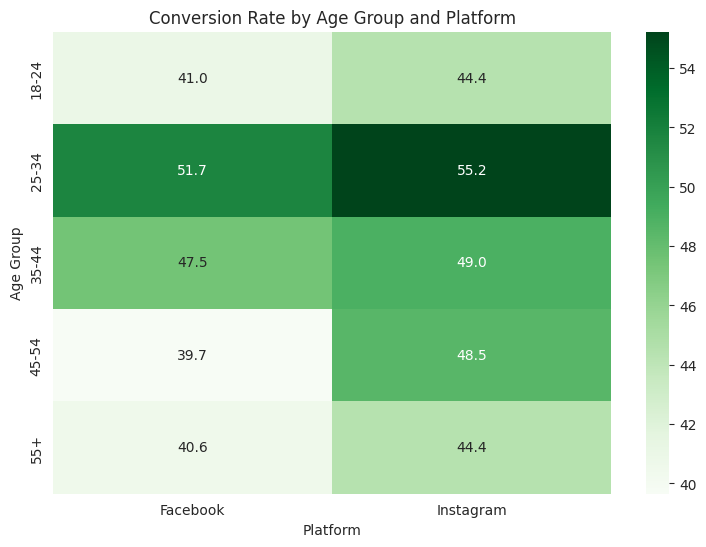

In [46]:
age_conversion = df.pivot_table(
    index="Age_Group",
    columns="ad_platform",
    values="conversion",
    aggfunc="mean"
) * 100

plt.figure(figsize=(9,6))

sns.heatmap(
    age_conversion,
    annot=True,
    fmt=".1f",
    cmap="Greens"
)

plt.title("Conversion Rate by Age Group and Platform")
plt.xlabel("Platform")
plt.ylabel("Age Group")

plt.show()

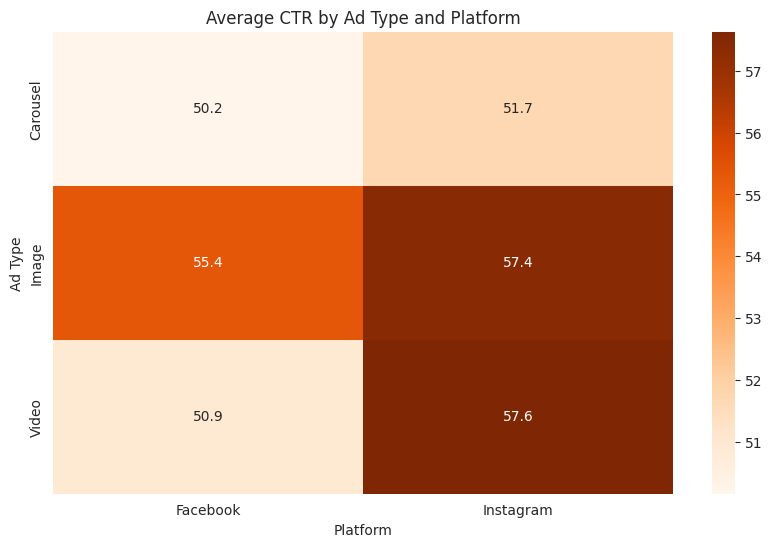

In [47]:
adtype_ctr = df.pivot_table(
    index="ad_type",
    columns="ad_platform",
    values="CTR",
    aggfunc="mean"
)

plt.figure(figsize=(10,6))

sns.heatmap(
    adtype_ctr,
    annot=True,
    fmt=".1f",
    cmap="Oranges"
)

plt.title("Average CTR by Ad Type and Platform")
plt.xlabel("Platform")
plt.ylabel("Ad Type")

plt.show()

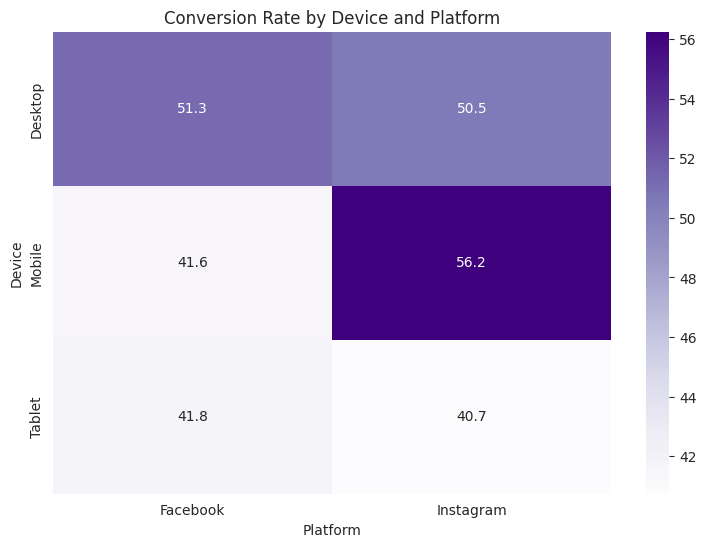

In [48]:
device_conversion = df.pivot_table(
    index="device_type",
    columns="ad_platform",
    values="conversion",
    aggfunc="mean"
) * 100

plt.figure(figsize=(9,6))

sns.heatmap(
    device_conversion,
    annot=True,
    fmt=".1f",
    cmap="Purples"
)

plt.title("Conversion Rate by Device and Platform")
plt.xlabel("Platform")
plt.ylabel("Device")

plt.show()

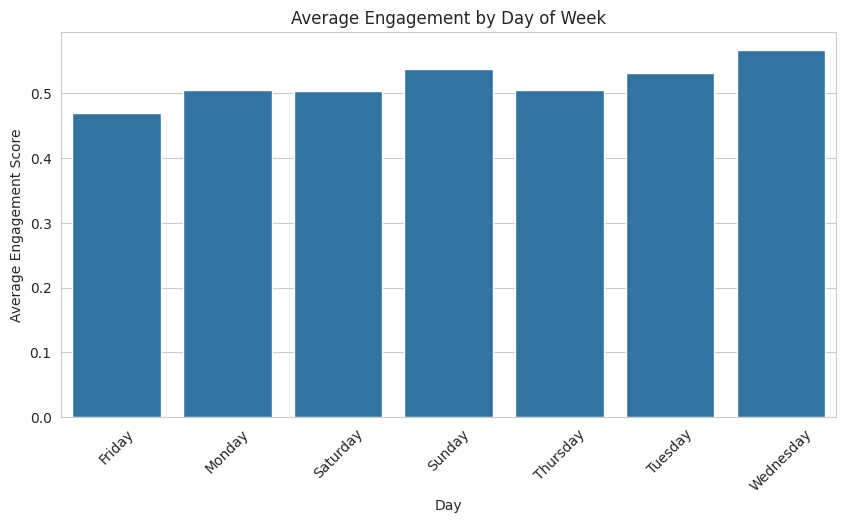

In [49]:
day_engagement = df.groupby("day_of_week")["engagement_score"].mean().reset_index()

plt.figure(figsize=(10,5))

sns.barplot(
    data=day_engagement,
    x="day_of_week",
    y="engagement_score"
)

plt.title("Average Engagement by Day of Week")
plt.xlabel("Day")
plt.ylabel("Average Engagement Score")

plt.xticks(rotation=45)

plt.show()

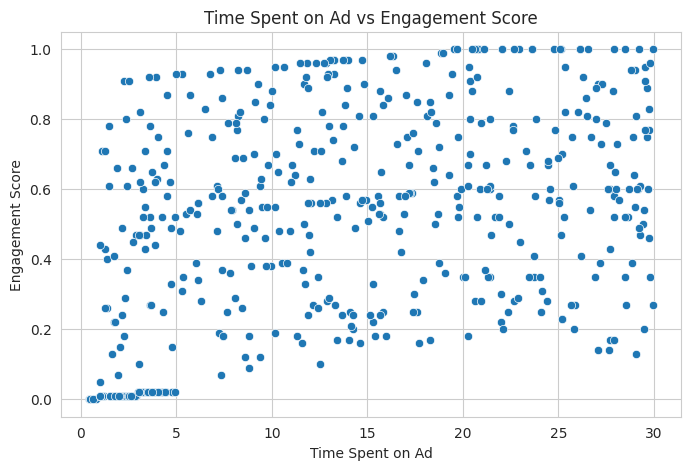

In [50]:
plt.figure(figsize=(8,5))

sns.scatterplot(
    data=df,
    x="time_spent_on_ad",
    y="engagement_score"
)

plt.title("Time Spent on Ad vs Engagement Score")
plt.xlabel("Time Spent on Ad")
plt.ylabel("Engagement Score")

plt.show()

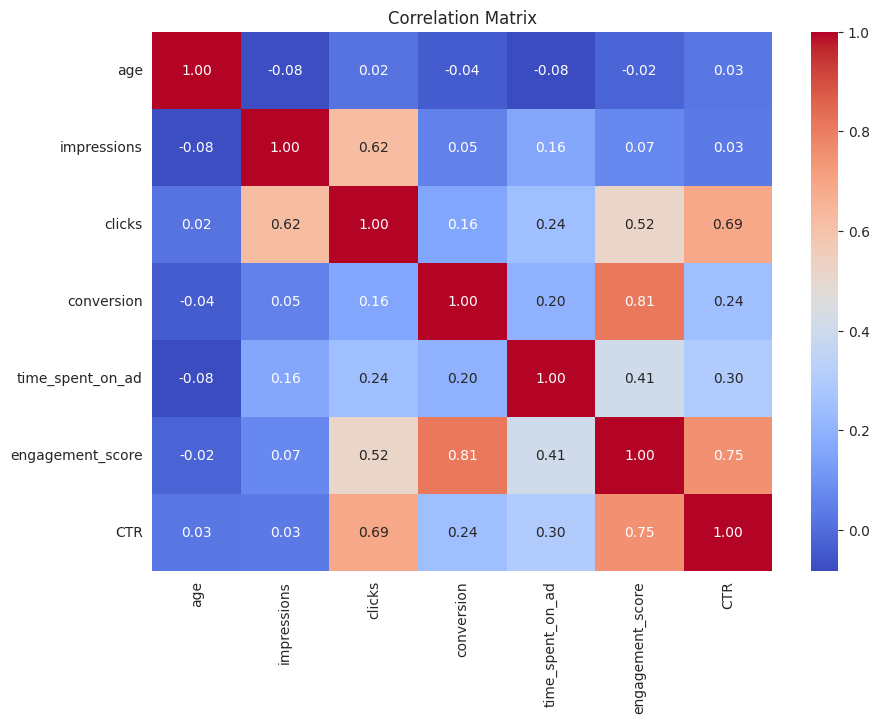

In [51]:
numeric_cols = [
    "age",
    "impressions",
    "clicks",
    "conversion",
    "time_spent_on_ad",
    "engagement_score",
    "CTR"
]

corr = df[numeric_cols].corr()

plt.figure(figsize=(10,7))

sns.heatmap(
    corr,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Matrix")

plt.show()